<a href="https://colab.research.google.com/github/AlejandroMev/Data-Scientist/blob/AutoMachine-Learning/5_5_2_AutoML_en_clasificaci%C3%B3n_y_en_regresi%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **AutoML en clasificación**



In [ ]:
# Reemplazo de los valores no conocidos por NaN:
openings=openings.replace([-1],[np.nan])
openings=openings.replace(['-1'],[np.nan])
openings=openings.replace(['unknown'],[np.nan])
openings=openings.replace(['Unknown / Non-Applicable'],[np.nan])

In [ ]:
# Incorporación de la columna (100K) como variable de salida:
openings['100K'] = openings['Avg Salary(K)'].apply(lambda x: 0 if x
< 100 else 1)

In [ ]:
# Eliminación de las columnas sin aportación en la predicción, repetitivas y
directamente correlacionadas con la salida:
openings.drop(['index','Job Description'], axis = 1, inplace = True)
openings.drop(['company_txt'], axis = 1, inplace = True)
openings.drop(['Salary Estimate','Lower Salary','Upper Salary','Avg Salary(K)'],
              axis = 1, inplace = True)

In [ ]:
# Imputación de valores y eliminación de la columna Competitors (por tener más
# del 50 % de los registros con NaN):
openings = openings.drop(columns = ['Competitors'])
openings['Headquarters'] =
openings['Headquarters'].fillna(openings['Headquarters'].mode()[0])
openings['Size'] =
openings['Size'].fillna(openings['Size'].mode()[0])
openings['Industry'] =
openings['Industry'].fillna(openings['Industry'].mode()[0])
openings['Sector'] =
openings['Sector'].fillna(openings['Sector'].mode()[0])
openings['Revenue'] =
openings['Revenue'].fillna(openings['Revenue'].mode()[0])
openings['Rating'] =
openings['Rating'].fillna(openings['Rating'].mean())
openings['Founded'] =
openings['Founded'].fillna(openings['Founded'].median())
openings['Age'] = openings['Age'].fillna(openings['Age'].median())

La información que manipulamos anteriormente se encuentra en el DataFrame **openings** de Pandas, pero es necesario colocarla en un H2OFrame para su uso en la plataforma. La principal diferencia en estas representaciones tabulares radica en que los datos no se encuentran en memoria del script, sino en un cluster H2O posiblemente
remoto. Para realizar la conversión puedes utilizar la función ***H2OFrame()*** de nuestra instancia.

In [ ]:
openingsH2O = h2o.H2OFrame(openings)

Otra posibilidad es que cargues los datos directamente en H2O con la función ***import_file()*** a la que le puedes pasar la ubicación y el nombre del archivo a leer.
Esto dejará los datos directamente en un **H2OFrame**, pero deberás hacer el preprocesamiento (valores faltantes, imputación, etc.) en esta plataforma, que resulta más complicado que con Pandas.

In [ ]:
# Hagamos un análisis exploratorio muy sencillo en H2O para ver las similitudes del
# H2OFrame con los DataFrames.

# Para obtener las dimensiones del H2OFrame.
openingsH2O.shape(742, 35)

# Para los nombres de las columnas.
openingsH2O.columns

In [ ]:
# table() - permite contabilizar la cantidad de valores únicos por columna.

# Hagámoslo con la variable de salida 100K:
openingsH2O['100K'].table()

El resultado anterior indica que **este problema de clasificación binaria tiene clases balanceadas**. Aquí es importante resaltar que la plataforma H2O realiza algunas tareas de preprocesamiento de manera automática, una de ellas es justamente el balanceo de
clase (por medio del parámetro **balance_classes**), pero también:

• Variables categóricas

• Estandarización

• Eliminación de variables con varianza cero

**Ahora podemos separar los datos en los conjuntos de entrenamiento (train) y de prueba (test)** mediante la función ***split_frame()*** del H2OFrame. El **parámetro ratio** indica la proporción de la separación; y ***destination_frames***, los nombres de los H2OFrames resultantes. Los conjuntos retornados los regresará en forma de lista que asignaremos a las variables train y test.

In [ ]:
train, test = openingsH2O.split_frame(ratios=[0.80],
destination_frames=['train', 'test'], seed=1)

Podemos utilizar nuevamente la función ***table()*** para ver la distribución de los registros en los conjuntos de entrenamiento y prueba. **Para garantizar reproducibilidad**, incluye el parámetro ***seed*** en la llamada a la función.

In [ ]:
train['100K'].table()
test['100K'].table()

El **último paso** antes de ejecutar el AutoML es **definir la columna objetivo** (100K) en una **variable** **Y** y los **predictores** en **X**:

In [ ]:
y = '100K'
X = list(openingsH2O.columns)
X.remove(y)

Una consideración importante para H2O es que cuando trata un problema de clasificación binaria, **la columna objetivo debe ser de tipo categórica**. Esto lo aseguras con la función ***asFactor()***:

In [ ]:
train[y] = train[y].asfactor()
test[y] = test[y].asfactor()

Ahora podemos ejecutar el autoaprendizaje estableciendo la configuración básica y ejecutando el entrenamiento con la funciones previamente analizadas: ***H2OAutoML()*** y ***train()*** respectivamente. A esta última le indicamos las columnas predictoras ***(X)***, la columna objetivo ***(y)*** y el H2OFrame con los datos de entrenamiento:

In [ ]:
aml = H2OAutoML(max_runtime_secs=90, seed=1)
aml.train(x = X, y = y, training_frame=train)

Aunque la función H2OAutoML incluye también un parámetro de semilla (**seed)**, H2O únicamente puede garantizar la reproducibilidad bajo ciertas condiciones. Por ejemplo, los modelos de Deep Learning no son reproducibles, por lo que habría que excluirlos con el parámetro ***exclude_algos***. Además, se debe indicar ***max_models*** porque ***max_runtime_secs*** tiene recursos limitados, lo que significa que **si los recursos informáticos disponibles no son los mismos entre ejecuciones,** **AutoML puede entrenar más modelos en una ejecución que en otra**. Considera esto si quieres obtener los mismos resultados en varias ejecuciones.

Al ejecutar las funciones anteriores, se obtendrá un reporte con las métricas definidas en problemas de clasificación para el mejor modelo, su matriz de confusión, tablas de ganancias, etc., sobre los datos de entrenamiento y de validación. En este caso, el algoritmo empleado en el mejor modelo es un ensamble con estrategia stacking
(**Stacked Ensemble**).

Seguramente te preguntarás de dónde se obtuvo el conjunto de validación. H2O AutoML utiliza validación cruzada de **5 folds (por defecto**) para validar los modelos internamente; es decir, estimar el rendimiento sin sacrificar una división de validación.
Esto, además, evita problemas estadísticos con su división de validación. Así, se producen métricas de entrenamiento (**del 80 % de los datos de train**) y métricas de validación (**con el 20 % restante**)

El objeto de AutoML incluye una tabla de clasificación de los mejores 10 modelos que se entrenaron, con el rendimiento de validación cruzada. Recuerda que si deseas puntuar los modelos en un conjunto de datos específico, puedes indicarlo en el argumento ***leaderboard_frame*** de ***train()*** y entonces, la tabla de clasificación mostrará las puntuaciones en ese conjunto de datos:

In [ ]:
aml.leaderboard

Los **modelos han sido ordenados por el auc, porque esta es la métrica de ordenamiento por defecto** que se usa en clasificación binaria, pero podrías cambiarla con el parámetro ***sort_metric*** de la función ***H2OAutoML()***. Si quieres imprimir todos los modelos entrenados, almacena la tabla como sigue:

In [ ]:
lb = aml.leaderboard
lb.head(rows=lb.nrows)

Con H2O AutoML es posible visualizar la importancia de las características **(columnas)** para cada uno de los modelos aplicados por medio de la función ***varimp()***. Para complementar el resultado utiliza ***varimp_heatmap()***, que te permitirá visualizar el impacto de manera gráfica:

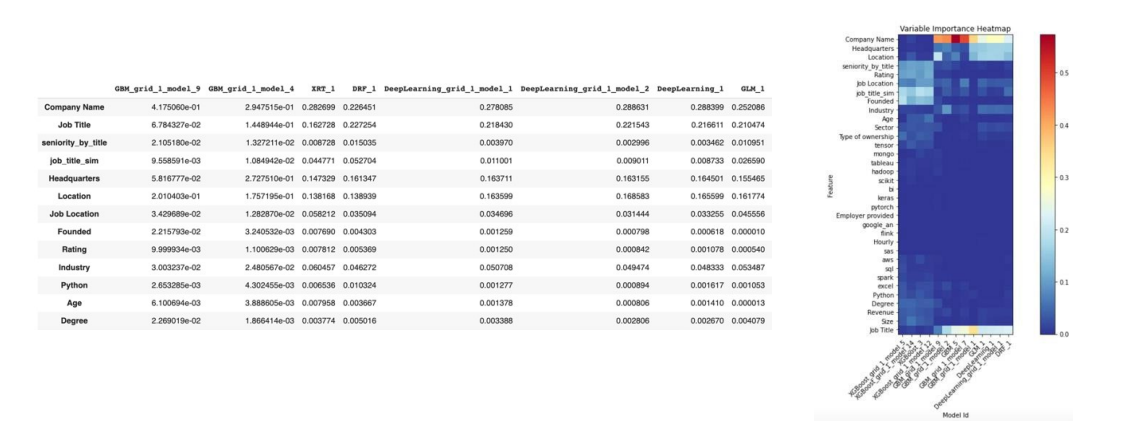

Si te fijas en los modelos del gráfico, no está incluido el mejor modelo, lo cual ocurre porque las funciones de importancia no están definidas en todos los algoritmos. Estos reportes te permiten analizar la posibilidad de disminuir los predictores para obtener modelos más simples sin comprometer en gran medida el rendimiento de los modelos.

La función ***get_best_model()*** regresa el mejor modelo obtenido **(1ra posición en leaderboard)**, e incluso te permite encontrar el mejor modelo para un cierto algoritmo y criterio especificado. Por ejemplo, la siguiente instrucción obtiene **el modelo con mejor rmse** de los que han sido construidos con el algoritmo ***xgboost***:

In [ ]:
xgb = aml.get_best_model(algorithm='xgboost', criterion='rmse')

Además, con la función ***get_best_model()*** o el atributo equivalente **leader** podrías evaluar el modelo en datos nunca vistos (**conjunto de prueba test**), a través de
***model_performance()***. Con el objeto obtenido podrías tener acceso a diversas métricas.

In [ ]:
perf = aml.leader.model_performance(test)
perf.accuracy()
perf.precision()

Estas funciones regresan, además de la métrica indicada, el umbral **(thresholds)**. **El valor del umbral se utiliza para convertir en etiquetas binarias de 0 o 1**, las puntuaciones numéricas de predicciones generadas por el modelo para cada registro del conjunto de datos. **Un cambio en el umbral de puntuación puede ajustar la manera en la que el modelo de ML asigna estas etiquetas**. El umbral también puede ser pasado como parámetro a la función, pero **por defecto tiene el valor de None**, que indica que se utilizará el umbral que maximiza la métrica. Por ejemplo, en el resultado anterior, la exactitud del modelo es: **accuracy = 0.624**, determinada con un umbral: **thresholds = 0.922**.

Por otra parte, H20 AutoML incluye la función ***explain()*** que fundamenta el porqué se llegó a la conclusión que el modelo es el mejor.

Esta función incluye, además de la matriz de confusión, varios gráficos de dependencia parcial.

In [ ]:
aml.leader.explain(test)

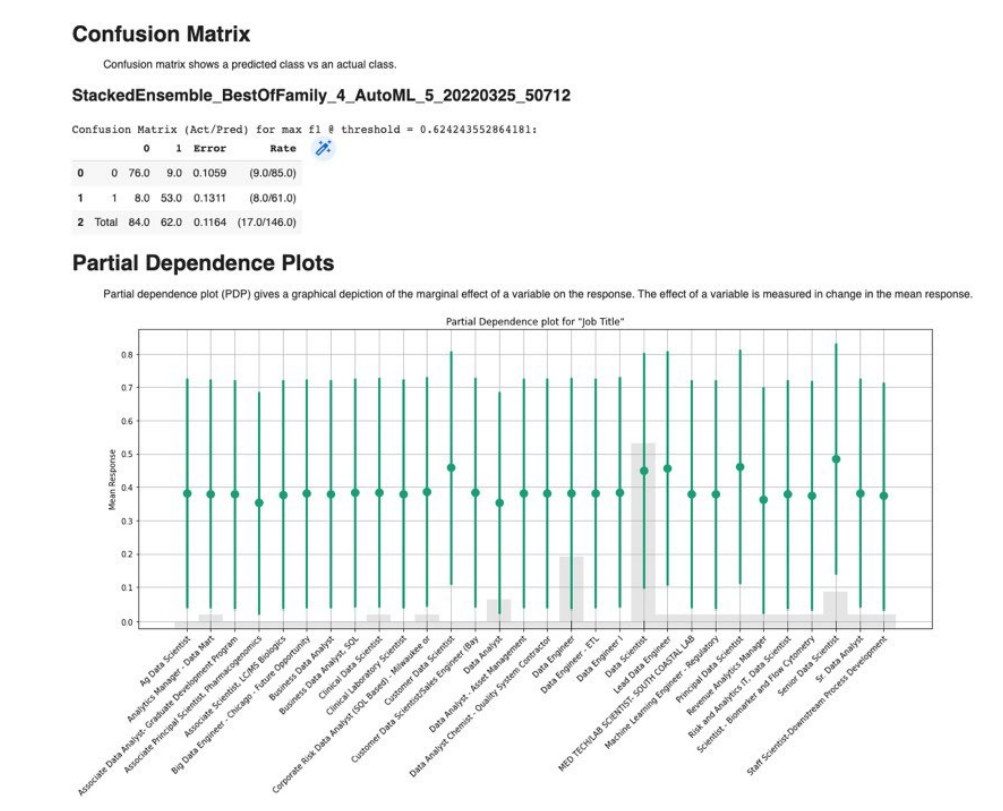

Por último, la función ***predict()*** genera las predicciones utilizando el mejor modelo.

In [ ]:
aml.predict(test)

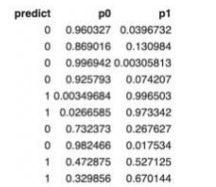

***predict()*** incluso proporciona valores de probabilidad asociados a cada conjunto para justificar la clasificación.

# **AutoML en regresión**

Para el problema de regresión, estimaremos el salario anual (Avg Salary(K)). Esto implica dos cambios en el preprocesamiento que ejecutaste anteriormente:
1. No generar la variable 100K
2. No borrar la variable Avg Salary(K)

Por lo que te recomendamos volver a cargar el csv. Después del preprocesamiento, ejecutemos nuevamente los pasos requeridos para AutoML que son aplicables a la regresión:

• Convertir el DataFrame de Pandas a H2OFrame:

In [ ]:
openingsH2O = h2o.H2OFrame(openings)

• Dividir en conjunto de entrenamiento y prueba:

In [ ]:
train, test = openingsH2O.split_frame(ratios=[0.80],
destination_frames=['train', 'test'])

• Establecer variable de salida y predictores. Observa que no es necesario convertir la salida a tipo categórico (en regresión la salida es numérica):

In [ ]:
y = 'Avg Salary(K)'
X = list(train.columns)
X.remove(y)

• Configurar y ejecutar el AutoML:

In [ ]:
aml = H2OAutoML(max_runtime_secs=90)
aml.train(x = X, y = y, training_frame = train)

• Imprimir la tabla de puntuación:

In [ ]:
aml.leaderboard

• Evaluar el modelo en datos nunca vistos:

In [ ]:
perf = aml.leader.model_performance(test)
perf.r2()

• Fundamentar la selección del mejor modelo con el conjunto de prueba. Podrás advertir que además de las gráficas de dependencia parcial, se generan visualizaciones de residuales y expectativa condicional:

In [ ]:
aml.leader.explain(test)

• Generar las predicciones utilizando el mejor modelo:

In [ ]:
aml.predict(test)